# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

  


In [345]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

df = sns.load_dataset('penguins')

In [346]:

class BivariateAnalyzer:
    def __init__(self,data): #inititalizing class template
        self.data = data.copy()
        print(f"{len(data)} x {len(data.columns)}") #displaying size and shape of data on init
        self.data.info()
        plt.figure(figsize=(8,5)) #setting 8x5 as default size
    def flippermass(self, foo): 
        plt.title(f'Distribution of flipper length and body mass for the {foo} species')
        sns.histplot(
            data=self.data[self.data['species']==foo], #only using data of species selected
            x='flipper_length_mm',
            y='body_mass_g')
    def islandmass(self,foo):
        plt.title('Distribution of body mass according to island')
        if(foo=='violinplot'): #allowing user to select either violin or boxplot to visualize distribution
            sns.violinplot(
                data=self.data,
                hue='island',
                y='body_mass_g')
        elif(foo=='boxplot'):
                sns.boxplot(
                data=self.data,
                hue='island',
                y='body_mass_g')
        else:
            print('Please choose either a boxplot or a violinplot.')
    def lendepth(self,foo):
        if(foo=='noreg'): #allowing user to select whether a regression line is displayed as well
            sns.scatterplot(
            data=self.data,
            x='bill_length_mm',
            y='bill_depth_mm',
            hue='species')
        elif(foo=='reg'):
            sns.lmplot(
            data=self.data,
            x='bill_length_mm',
            y='bill_depth_mm',
            hue='species')
        else:
            print('Please choose to either have a regression line (reg) or not (noreg)')
    def massflipper_sex(self,foo):
        if(foo=='noreg'):
            sns.scatterplot(
            data=self.data,
            x='body_mass_g',
            y='flipper_length_mm',
            hue='sex')
        elif(foo=='reg'):
            sns.lmplot(
            data=self.data,
            x='body_mass_g',
            y='flipper_length_mm',
            hue='sex')
        else:
            print('Please choose to either have a regression line (reg) or not (noreg)')
    def massdepth_islandspecific(self,foo):
        plt.title(f'Distribution of mass and bill depth on {foo} island')
        sns.scatterplot(
        data=self.data[self.data['island']==foo], #only using data from selected island
        x='body_mass_g',
        y='bill_depth_mm',
        hue='sex')

In [347]:
analyzer = BivariateAnalyzer(df)

344 x 7
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


<Figure size 800x500 with 0 Axes>

##  In this analysis, I wish to see wgat is the most frequent flipper length and body mass combination for the Gentoo species.

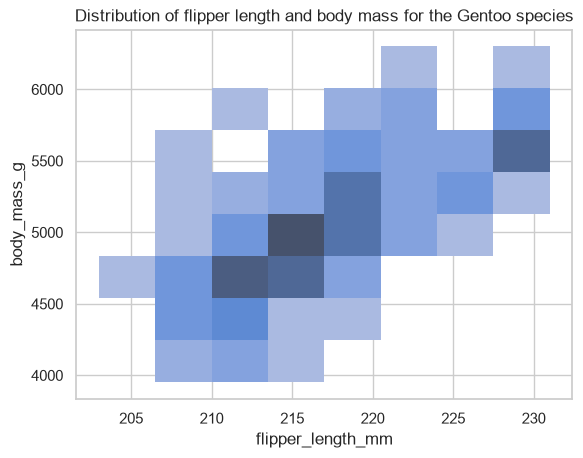

In [348]:
analyzer.flippermass('Gentoo')

##  In this analysis, I wish to see what is the most frequent flipper length and body mass combination for the Adelie species.

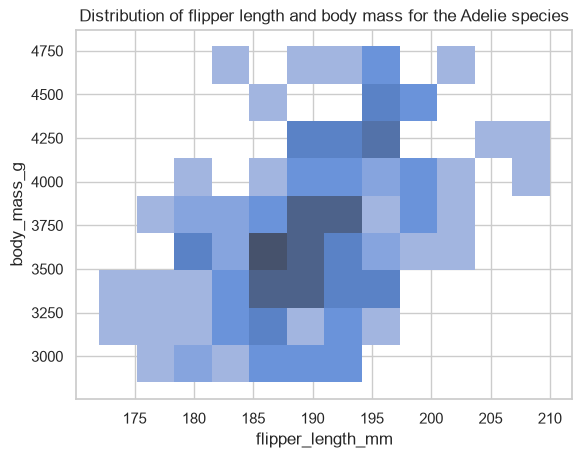

In [349]:
analyzer.flippermass('Adelie')

## In this analysis, I wish to see what is the five-quartile summary (minimum, 25th percentile, median, 75th percentile, maximum) of body mass on each island.

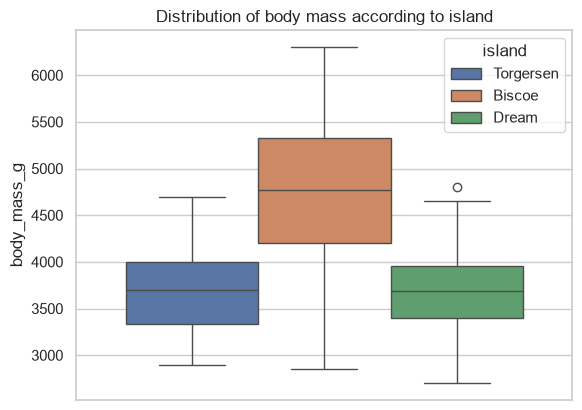

In [350]:
analyzer.islandmass('boxplot')

##  In this analysis, I wish to see what is the width and height of distribution of body mass on each island.

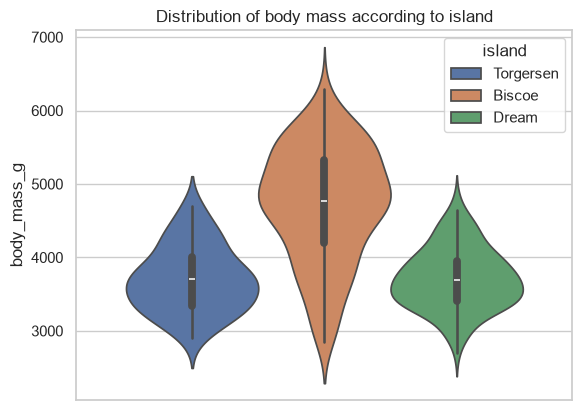

In [351]:
analyzer.islandmass('violinplot')

## In this analysis, I wish to see how bill depth and length are related in each species. In other words, if some species have a stronger relation between bill depth and length than others.

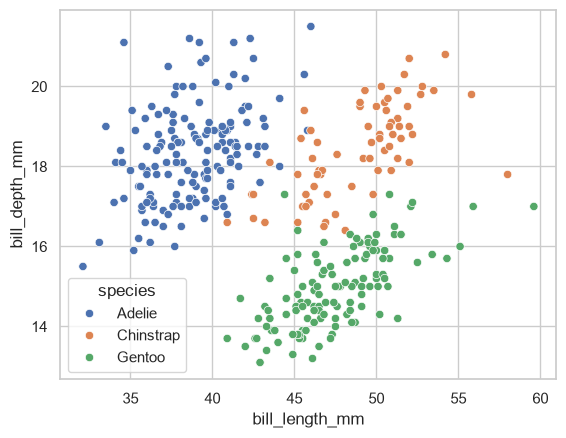

In [352]:
analyzer.lendepth('noreg')

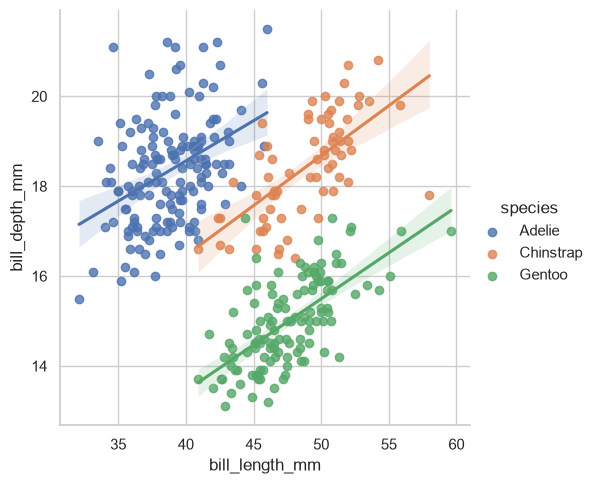

In [353]:
analyzer.lendepth('reg')

## In this analysis, I wish to see how flipper length and body mass are related according to sex.

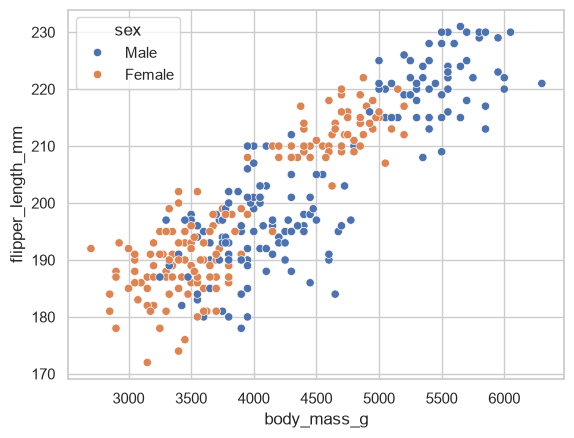

In [354]:
analyzer.massflipper_sex('noreg')

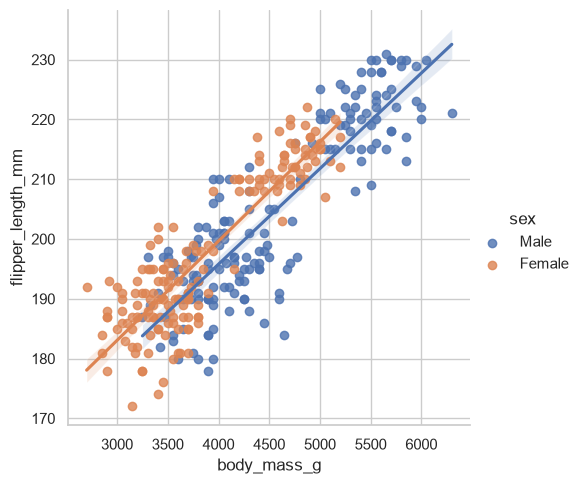

In [355]:
analyzer.massflipper_sex('reg')

## In this analysis, I wish to see how bill depth and body mass are related according to sex, on the specific island of Biscoe.

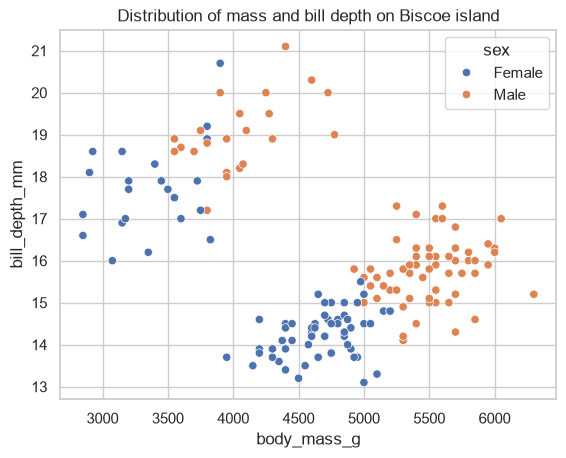

In [356]:
analyzer.massdepth_islandspecific('Biscoe')